## Task 1 • Python di base sui dati forniti

Consegna: sui quattro file forniti dal docente, svolgere i primi calcoli con strutture dati, cicli e funzioni Python, senza metodi di analisi Pandas.

1. Leggere products.csv e sales.json e convertirli con .to_dict(orient="records") in liste di dizionari; costruire regions come dizionario {RegionID: (State, SalesRegion)} e il set delle categorie.

In [5]:
import pandas as pd #importo Pandas con l'abbreviazione standard pd

# Carico i file richiesti dalla traccia, products.csv e sales.json
products_df = pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-products.csv") 
sales_df = pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json")

# Converto entrambi in liste di dizionari con .to_dict
products_list = products_df.to_dict(orient="records") 
sales_list = sales_df.to_dict(orient="records") 

# Carico anche regions, anche se non è richiesto, per cui è ambiguo: come faccio altrimenti a trasformarlo in dizionario?
regions_df = pd.read_excel("ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx")  

# Costruisco regions_dict come dizionario, RegionsID come chiave, State e SalesRegion come valore della tupla
regions_dict = {}
for r in regions_df.to_dict(orient="records"):
    regions_dict[r["RegionID"]] = (r["State"], r["SalesRegion"])

# Costruisco il set delle categorie richiamando le categorie in product list
categories = {p["Category"] for p in products_list}
print(categories)
    

{'Giochi da tavolo', 'Outdoor', 'Giocattoli'}


2. Con una list comprehension e un costrutto if/elif/else assegnare a ogni prodotto la fascia di prezzo: Bassa sotto 20 €, Media fino a 60 €, Alta oltre.

In [6]:
# La traccia, come sopra, risulta ambigua: non posso inserire un elif in una list comp, per cui proocedo come segue:
# Passo 1. Definisco una funzione fascia_prezzo con if/elif/else: 

def fascia_prezzo(prezzo):
    if prezzo<20:
        return "Fascia Bassa"
    elif prezzo <=60:
        return "Fascia Media"
    else:
        return "Fascia Alta"

# Passo 2. Definisco la List_comp usando una keywords FasciaPrezzo

[dict(p, FasciaPrezzo=fascia_prezzo(p["ListPrice"])) for p in products_list]

[{'ProductID': 1,
  'ProductName': 'Bici Junior',
  'Category': 'Outdoor',
  'ListPrice': 129.0,
  'FasciaPrezzo': 'Fascia Alta'},
 {'ProductID': 2,
  'ProductName': 'Bici BMX',
  'Category': 'Outdoor',
  'ListPrice': 189.0,
  'FasciaPrezzo': 'Fascia Alta'},
 {'ProductID': 3,
  'ProductName': 'Monopattino',
  'Category': 'Outdoor',
  'ListPrice': 79.0,
  'FasciaPrezzo': 'Fascia Alta'},
 {'ProductID': 4,
  'ProductName': 'Pallone Calcio',
  'Category': 'Outdoor',
  'ListPrice': 19.9,
  'FasciaPrezzo': 'Fascia Bassa'},
 {'ProductID': 5,
  'ProductName': 'Racchette Beach',
  'Category': 'Outdoor',
  'ListPrice': 14.5,
  'FasciaPrezzo': 'Fascia Bassa'},
 {'ProductID': 6,
  'ProductName': 'Puzzle 1000',
  'Category': 'Giochi da tavolo',
  'ListPrice': 17.9,
  'FasciaPrezzo': 'Fascia Bassa'},
 {'ProductID': 7,
  'ProductName': "Gioco dell'Oca",
  'Category': 'Giochi da tavolo',
  'ListPrice': 12.5,
  'FasciaPrezzo': 'Fascia Bassa'},
 {'ProductID': 8,
  'ProductName': 'Scacchi Legno',
  'Cate

3. Scrivere la funzione fatturato_categoria (vendite, prodotti, categoria) che con un ciclo for somma SalesAmount della categoria, salta i valori mancanti e restituisce il totale con return.

In [7]:
# Definisco una funzione come segue: 

# Passo 1. Definizio una funzionefatturato_categoria con gli argomenti indicati dal punto 3
# Passo 2. Creto un set vuoto "Category ID"; per tutte le categorie di prodotti in products
            # se la categoria di prodotto è quella richiesta, la aggiungo al set "CategoryID"
#Passo 3. Uso il ciclo for per la somma come segue:
#Passo 4. Total è il contatore, conto tutte le vendite v in Sales, leggo l'importo e lo salvo in amount
#Passo 5. Uso If con And: prodotto venduto appartiene alla sua categoria, non è None è l'importo non è None (salta valori)
#Passo 6. Vendite con amount None non sono sommate, dunque aggiunge l'importo al totale

def fatturato_categoria(sales,products,category):
    categoryID= set()
    for p in products:
        if p["Category"]==category:
            categoryID.add(p["ProductID"])

    total=0
    for v in sales:
            amount=v["SalesAmount"]
            if v["ProductID"] in categoryID and amount is not None and amount==amount:
                total +=amount
        
    return total


4. Con un ciclo while contare le transazioni necessarie a superare 10.000 € di fatturato cumulato; mostrare le prime cinque transazioni con vendite [:5].

In [8]:
# Seguendo la traccia usiamo un Ciclo While per scorrere tutti gli importi una alla volta, le somma e si ferma fino 
# all'importo di 10.000; inoltre usiamo un contatore per dire quante iterazioni servono

# Passo 1. Inizialiazzo somma, contatore, indice = 0
# Passo 2. Uso il While: se la somma è minore di 10.000 scorro fino a che i non è 10.000 con len
# Passo 3. Come sopra, impongo una condizione con su amount
# Passo 4. Faccio scorrere l'indice dentro il While ma fuori dall'If (sennò non termina)
# Passo 5. Condizione di slicing con [:5] che mi stampa le prime 5 transazioni in lista

somma = 0
contatore = 0
i = 0

while somma <=10000 and i <len(sales_list):
    amount = sales_list[i]["SalesAmount"]
    if amount is not None and amount == amount:
        somma += amount
    contatore +=1
    i +=1

print("Transazioni necessarie:", contatore)
print("Somma del fatturato:", somma)
for v in sales_list[:5]:
    print(v)


Transazioni necessarie: 56
Somma del fatturato: 10164.8
{'SalesID': 1194, 'ProductID': 6, 'RegionID': 7, 'ResellerID': 283, 'SalesDate': '2023-01-01', 'Quantity': 4.0, 'SalesAmount': 71.6}
{'SalesID': 859, 'ProductID': 6, 'RegionID': 8, 'ResellerID': 28, 'SalesDate': '2023-01-02', 'Quantity': 7.0, 'SalesAmount': nan}
{'SalesID': 1747, 'ProductID': 12, 'RegionID': 3, 'ResellerID': 281, 'SalesDate': '2023-01-02', 'Quantity': 2.0, 'SalesAmount': 118.0}
{'SalesID': 279, 'ProductID': 3, 'RegionID': 7, 'ResellerID': 128, 'SalesDate': '2023-01-02', 'Quantity': 3.0, 'SalesAmount': nan}
{'SalesID': 1470, 'ProductID': 1, 'RegionID': 6, 'ResellerID': 137, 'SalesDate': '2023-01-04', 'Quantity': 4.0, 'SalesAmount': nan}


Vincolo: Pandas si usa solo per leggere i file e convertirli; somme, conteggi e classificazioni si calcolano con costrutti Python.

Definizione richiesta: differenza tra lista, tupla, set e dizionario per mutabilità, ordine, duplicati e modalità di accesso (indice o chiave).

Criterio di completamento: len() di lista prodotti, dizionario regions e set delle categorie riportata; fascia assegnata a ogni prodotto; fatturato per categoria da fatturato_categoria(), da confrontare con il Task 3b.

***

In Python ci sono quattro modi principali per raccogliere più valori in una variabile:

La Lista ([10, 20, 30]) è un elenco ordinato e modificabile: ammette duplicati e si legge tramite l'indice (lista[0]).

La Tupla (("Milano", "Italia")) è come una lista, ordinata, con duplicati e accesso tramite l'indice, ma, dopo la creazione non è più modificabile. È ideale quindi per dati che devono rimanre fissi, ad esempio, uno città è un'area di venditaò

Il Set ({"Outdoor", "Giocattoli"}) è un insieme che è modificabile, ma è senza ordine e non contiene duplicati. Inoltre, non ha indici: possiamo solo controllare, proprio come in un insieme, se un elemento c'è. È utile per trattare valori unici come, ad esempio, le categorie. 

Il Dizionario ({1: ("Italia", "Sud Europa")}) è un insieme modificabile formato da coppie chiave-valore: si legge per chiave, ad esempio (regions_dict[1]): le chiavi sono uniche e i valori, invece, possono ripetersi.

## Task 2 • Lettura e ispezione dei dati

Consegna: leggere i quattro file in DataFrame e descriverne struttura e contenuto prima di qualsiasi modifica.

1. Leggere i file con pd.read_csv(), pd.read_excel() e pd.read_json() e riportare per ciascuno shape, info(), .head() e .tail().

In [9]:
# Importo pandas con l'abbrevazione standard pd 
# Passo 1. Leggo i quattro file con pd.read_csv/excel/json

import pandas as pd

product_df= pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-products.csv")

sales_df= pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json")

resellers_df= pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-resellers.csv")

regions_df= pd.read_excel("ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx")

# Passo 2. Per evitare di ripetere le quattro richieste, le organizzo con un ciclo for in cui richiamo nome e data_frame
# Passo 3. Mostro shape, info, head e tail, con display le lascio disponibili alla lettura

for name, df in [("products", products_df), ("sales", sales_df),
                 ("resellers", resellers_df), ("regions", regions_df)]:
    print("=====", name, "=====")
    print("shape:", df.shape)
    df.info()
    display(df.head())
    display(df.tail())

===== products =====
shape: (12, 4)
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    12 non-null     int64  
 1   ProductName  12 non-null     str    
 2   Category     12 non-null     str    
 3   ListPrice    12 non-null     float64
dtypes: float64(1), int64(1), str(2)
memory usage: 788.0 bytes


,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0
3,4,Pallone Calcio,Outdoor,19.9
4,5,Racchette Beach,Outdoor,14.5


,ProductID,ProductName,Category,ListPrice
7,8,Scacchi Legno,Giochi da tavolo,34.0
8,9,Costruzioni 500,Giocattoli,39.9
9,10,Bambola Classica,Giocattoli,24.9
10,11,Robot RC,Giocattoli,89.0
11,12,Macchinina RC,Giocattoli,59.0


===== sales =====
shape: (2000, 7)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SalesID      2000 non-null   int64  
 1   ProductID    2000 non-null   int64  
 2   RegionID     2000 non-null   int64  
 3   ResellerID   2000 non-null   int64  
 4   SalesDate    2000 non-null   str    
 5   Quantity     1900 non-null   float64
 6   SalesAmount  1900 non-null   float64
dtypes: float64(2), int64(4), str(1)
memory usage: 129.0 KB


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
0,1194,6,7,283,2023-01-01,4.0,71.6
1,859,6,8,28,2023-01-02,7.0,NaN
2,1747,12,3,281,2023-01-02,2.0,118.0
3,279,3,7,128,2023-01-02,3.0,NaN
4,1470,1,6,137,2023-01-04,4.0,NaN


...

,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
0,1,1,14,65,0.131,1,0
1,2,7,9,149,0.117,1,0
2,3,6,21,1,0.065,2,0
3,4,4,18,162,0.011,1,1
4,5,4,22,98,0.120,0,0


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
295,296,5,18,145,0.218,1,0
296,297,8,17,104,0.048,0,0
297,298,4,16,141,0.055,2,0
298,299,3,13,113,0.164,0,0
299,300,1,12,116,0.072,0,0


===== regions =====
shape: (9, 3)
<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   RegionID     9 non-null      int64
 1   State        9 non-null      str  
 2   SalesRegion  9 non-null      str  
dtypes: int64(1), str(2)
memory usage: 515.0 bytes


,RegionID,State,SalesRegion
0,1,Italia,Sud Europa
1,2,Francia,Sud Europa
2,3,Spagna,Sud Europa
3,4,Germania,Centro Europa
4,5,Austria,Centro Europa


,RegionID,State,SalesRegion
4,5,Austria,Centro Europa
5,6,Svizzera,Centro Europa
6,7,Svezia,Nord Europa
7,8,Norvegia,Nord Europa
8,9,Danimarca,Nord Europa


2. Con describe() individuare minimo, massimo e media di Quantity e SalesAmount; convertire le due colonne in array NumPy e calcolare con un'operazione vettoriale il prezzo unitario di ogni vendita.

In [10]:
# Importo NumPy con l'abbreviazione standard np
import numpy as np

# Passo 1. Con .describe() leggo da Sales, Quantity e SalesAmount, aggiungo display per rendere i valori visibili
display(sales_df[["Quantity", "SalesAmount"]].describe())

#Passo 2. Converto Quantity e SalesAmount in Array Numpy
quantity = np.array(sales_df["Quantity"])
sales_amount = np.array(sales_df["SalesAmount"])

#Passo 3. Una volta convertiti in Array Numpy, divido tra Sales amount e quantity, stampo poi il risultato
prezzo_unitario = sales_amount/quantity

print(prezzo_unitario)

,Quantity,SalesAmount
count,1900.000000,1900.000000
mean,4.966316,294.776579
std,2.206535,305.261212
min,1.000000,12.500000
25%,3.000000,89.000000
50%,5.000000,177.000000
75%,6.000000,387.000000
max,14.000000,2457.000000


[17.9  nan 59.  ... 19.9 19.9 39.9]


3. Selezionare con loc[] e una maschera booleana i prodotti di una categoria con ListPrice superiore a 30 €; con iloc[] le righe da 10 a 19 e le prime tre colonne di sales.

In [11]:
#Passo 1. Definisco una maschera booleana, ovvero, True per quei prodotti con prezzo superiore a 30
#Passo 2. Prendo Outdoor da Category, e products da ListPrice

maschera_booleana = (products_df["Category"]=="Outdoor") & (products_df["ListPrice"] >30) 

#Passo 3. con loc richiamo la maschera booleana e visualizzo i prodotti >30
product_df.loc[maschera_booleana]

# Passo 4. con iloc richiamo le righe da 10 a 19 [10:20] e le prime 3 colonne di sales_df
sales_df.iloc[10:20,0:3]


,SalesID,ProductID,RegionID
10,218,1,8
11,1136,1,9
12,1326,3,4
13,1063,9,7
14,1606,10,8
15,1283,12,1
16,98,3,4
17,156,6,8
18,1642,12,5
19,1644,4,7


Definizione richiesta: differenza tra Series e DataFrame e tra locl[] (selezione per etichetta) e iloc[] (selezione per posizione).

Vincolo: nessuna modifica ai DataFrame in questo task: solo lettura, descrizione e selezione.

Criterio di completamento: per ogni DataFrame sono riportati righe, colonne, tipi e conteggio dei non nulli; la selezione con iloc[] restituisce 10 righe e 3 colonne.

***

Series e DataFrame, loc[] e iloc[]

Una Series in Pandas è una colonna di dati dotata di un indice, ha una sola dimensione e ha un solo tipo (per esempio sales_df["SalesAmount"]). 

Un DataFrame in Pandas è una tabella, invece, che ha due dimensioni ed è formata da più Series con lo stesso indice, ciascuna con un proprio tipo (per esempio sales_df).

loc[] seleziona per etichetta (ovvero per nome di riga e di colonna), e accetta anche maschere booleane; negli intervalli che selezioniamo l'estremo finale è sempre incluso (in loc[10:19], abbiamo 10 righe, dalla 10 alla 19). 

iloc[], invece, seleziona per posizione, cominciando a contare da 0; ancora, a differeza di prima, l'estremo finale non è incluso (un iloc[10:20] ci dà 10 righe). 

## Task 3a • Dati mancanti, filtri e ordinamento

Consegna: rendere il DataFrame delle vendite pronto per l'analisi, trattando i valori mancanti e isolando i sottoinsiemi richiesti.

1. Contare i NaN per colonna con .isna().sum() e calcolarne la percentuale sul numero totale di righe.

In [12]:
# Passo 1. Isolo le colonne con valore NaN. Dal task precedente tramite .info() 
        # solo in Sales (Quantity e Sales Amount) sono presenti Nan

# Passo 2. Faccio il conteggio con .isna() +.sum() e calcolo la percentuale dal totale delle righe
nan_count = sales_df.isna().sum()
nan_percentuale = nan_count / len(sales_df) * 100

# Passo 3. Faccio un print per verificare
print(nan_count)
print(nan_percentuale)

SalesID          0
ProductID        0
RegionID         0
ResellerID       0
SalesDate        0
Quantity       100
SalesAmount    100
dtype: int64
SalesID        0.0
ProductID      0.0
RegionID       0.0
ResellerID     0.0
SalesDate      0.0
Quantity       5.0
SalesAmount    5.0
dtype: float64


2. Imputare Quantity con la mediana della colonna tramite fillna() ed eliminare con dropna() le righe con SalesAmount mancante, dichiarando il numero di righe rimosse.

In [13]:
# Passo 1. Mi calcolo la mediana di sales_df tramite .median() assegnando a median_q
#          La mediana è il valore centrale della colonna
median_q = sales_df["Quantity"].median()

# Passo 2. Utilizzo il fillna in median_q, ovvero, vado a riempire i Nan in Quantity con la mediana calcolata
sales_df["Quantity"] = sales_df["Quantity"].fillna(median_q)

# Passo 3. Faccio un print e con isna e sum verifico che il risultato sia 0, perché dopo fillna non devo avere NaN
print(sales_df["Quantity"].isna().sum())  # deve dare 0
sales_df["SalesAmount"].isna().sum()

# Passo 4. Recupero le righe originali (2000)
righe_or = len(sales_df)

# Passo 5. Elimino con dropna le righe NaN in Sales Amount e riassegno poi il tutto a sales_df
sales_df = sales_df.dropna(subset=["SalesAmount"])
# Passo 6. Conteggio righe dopo il drop
righe_post = len(sales_df)

# Passo 7. Conteggio delle righe, primo risultato 100, secondo 2000-100, ovvero 1900
print("Righe rimosse:", righe_or - righe_post)
print("Righe rimaste:", righe_post)

0
Righe rimosse: 100
Righe rimaste: 1900


In [16]:
# Verifo i NaN come da richiesta di completamento 

nan_prima = pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json").isna().sum()
nan_dopo = sales_df.isna().sum()

tabella_nan = pd.DataFrame({"NaN prima": nan_prima, "NaN dopo": nan_dopo})
display(tabella_nan)

,NaN prima,NaN dopo
SalesID,0,0
ProductID,0,0
RegionID,0,0
ResellerID,0,0
SalesDate,0,0
Quantity,100,0
SalesAmount,100,0


3. Con query() estrarre le transazioni con SalesAmount superiore al 90° percentile (quantile(0.9)) e ordinarle con sort_values() per data crescente e importo decrescente.

In [15]:
# Passo 1. Calcolo il 90 percentile con .quantile(0.9) su SalesAmount
trans_90 = sales_df["SalesAmount"].quantile(0.9)

# Passo 2. Stampo il risultato del calcolo
print ("90° Percentile", trans_90)

# Passo 3. Utilizzo query() che mi estrae tutte le transazioni superiore al 90 percentile, 
#          Ho usato una f-string all'interno di query come mostrato da Tommaso a lezione. 
top_sort = sales_df.query(f"SalesAmount > {trans_90}")

# Passo 4. Ordino con sort values SalesDate e Sales Amount per data crescente
top_ordinate = top_sort.sort_values(by=["SalesDate", "SalesAmount"], ascending=[True, False])

# Passo 5. Stampo il risultato
top_ordinate.head(10)

90° Percentile 756.0


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
32,1045,2,4,82,2023-01-16,6.0,1134.0
49,1872,2,7,204,2023-01-25,5.0,945.0
52,1639,1,3,299,2023-01-27,9.0,1161.0
102,296,2,9,202,2023-02-25,5.0,945.0
118,1462,2,2,224,2023-03-03,5.0,945.0
121,1221,1,8,149,2023-03-05,8.0,1032.0
123,1753,2,8,151,2023-03-05,5.0,945.0
168,283,2,2,100,2023-03-30,11.0,2079.0
217,1679,1,4,22,2023-04-27,5.0,774.0
221,832,2,4,82,2023-04-28,6.0,1134.0


Definizione richiesta: imputazione dei dati mancanti: cos'è, quando preferire media, mediana o eliminazione della riga e quale effetto ha ciascuna scelta sulla distribuzione.

Attenzione: la mediana si calcola sui valori presenti prima del fillna(); dopo l'imputazione .isna() sum() di Quantity vale O.

Criterio di completamento: tabella dei NaN prima e dopo il trattamento; numero di righe eliminate riportato in Markdown;
filtro e ordinamento verificati con head (10).

***

Imputazione dei dati mancanti

L'imputazione è una sostituzione di valori mancanti, i NaN, con un valore stimato, per non perdere le righe che li contengono. 

La media la utilizziamo quando i valori della distribuzione sono più o meno regolari e non ci sono Outlier: essendo sensibile a valori estremi riduce la variabilità. 

La mediana, invece, la utlizziamo quando le distribuzioni sono asimetriche e sono presenti Outlier in quanto la mediana non ne è influenzata. La preferiamo quindi quando ci sono valori estremi. 

L'eliminazione della riga la usiamo quando i valori mancanti o sono pochi oppure e non possiamo fare una stima affidabile dei valori che mancano. In questo caso, tuttavia, perdiamo l'informazione. 

Esercizio: Quantity imputata con la mediana, calcolata sui valori presenti prima del fillna(); eliminate 100 righe su 2000 (5%) senza SalesAmount.

## Task 3b • Aggregazioni e combinazione dei DataFrame

Consegna: costruire una tabella unica delle vendite e calcolare il fatturato per le principali chiavi di analisi.

1. Unire sales con products e regions tramite merge() su ProductID e RegionID (how="left") e verificare che il numero di righe resti quello di sales.

In [18]:
# Passo 1. Numero di righe in sales_df con len
righe_sales = len(sales_df)

# Passo 2. Faccio il merge, il primo 
        # aggiungo ad ogni vendita i dati del prodotto tramite Product ID
        # Faccio il secondo merge, al risultato aggiungo i dati regione tramite la chiave RegionID.
merge_sales = (sales_df
               .merge(product_df, on="ProductID", how="left")
               .merge(regions_df, on="RegionID", how="left"))

# Passo 3. Faccio un check  per verificare che il numero di righe resti quello di sales
print("Righe sales:", righe_sales)
print("Righe dopo il merge:", len(merge_sales))
print("Uguali:", righe_sales == len(merge_sales))

Righe sales: 1900
Righe dopo il merge: 1900
Uguali: True


2.   Con groupby() e agg() calcolare fatturato totale, quantità totale e numero di transazioni per Category e per SalesRegion, ordinati per fatturato decrescente.

In [19]:
# Passo 1. Faccio il primo group by per Categoria
            # utilizzo .agg per calcolare fatturato, quantità e transazioni con le relative somme e count
            #   con sort_values li ordino in modo decrescente

totale_categoria = (merge_sales.groupby("Category")
                    .agg(fatturato = ("SalesAmount", "sum"),
                    quantità = ("Quantity", "sum"),
                    transazioni = ("SalesID","count"))
                    .sort_values("fatturato", ascending=False))

# Passo 2. Faccio il secondo group by per SalesRegion
            # stesso codice di sopra
totale_region = (merge_sales.groupby("SalesRegion")
                    .agg(fatturato = ("SalesAmount", "sum"),
                    quantità = ("Quantity", "sum"),
                    transazioni = ("SalesID","count"))
                    .sort_values("fatturato", ascending=False))

# Passo 3. Faccio un print e con display le tengo disponibili alla visualizzazione
print("Fatturato per categoria")
display(totale_categoria)

print("Fatturato per regione di vendita")
display(totale_region)

Fatturato per categoria


,fatturato,quantità,transazioni
Category,,,
Outdoor,331998.4,3800.0,767
Giocattoli,174832.0,3225.0,644
Giochi da tavolo,53245.1,2416.0,489


Fatturato per regione di vendita


,fatturato,quantità,transazioni
SalesRegion,,,
Centro Europa,201062.2,3413.0,698
Nord Europa,190189.0,3175.0,633
Sud Europa,168824.3,2853.0,569


3. Separare le vendite 2025 dalle altre con un filtro e ricomporle con pd.concat(), verificando che la somma delle righe coincida con l'originale.

In [23]:
# Passo 1. Separo le vendite con str.split (sono stringhe)
anno_vendite = merge_sales["SalesDate"].str.split("-").str[0]

# Passo 2. Primo filtro, anno in cui le vendite sono uguali a "2025"
vendite_2025 = merge_sales[anno_vendite == "2025"]
# Passo 3. Secondo filtro, anno in cui le vendite non sono uguali a "2025" ovvero tutte le altre righe
vendite_altre = merge_sales[anno_vendite != "2025"]

# Passo 4. Uso .concat per ricomporre le righe una sotto le altre
concat = pd.concat([vendite_2025, vendite_altre])

# Passo 5.Check della somma delle righe dello split che deve coincidere con l'originale.
print("Vendite 2025:", len(vendite_2025))
print("Altre vendite:", len(vendite_altre))
print("Somma:", len(vendite_2025) + len(vendite_altre))
print("Originale:", len(merge_sales))
print("Coincide:", len(concat) == len(merge_sales))

Vendite 2025: 640
Altre vendite: 1260
Somma: 1900
Originale: 1900
Coincide: True


Definizione richiesta: differenza tra merge () (unione su colonne chiave), join() (unione sull'indice) e concat() (accodamento
di righe o colonne).

Criterio di completamento: righe dopo il merge uguali a quelle di sales; due tabelle aggregate; categoria con il fatturato più alto indicata in Markdown.

***

Definizione di merge(), join() e concat()

Il merge() unisce due tabelle sui valori di una o più colonne chiave in comune (per esempio nel nostro caso è ProductID): lavora proprio come un join di SQL in quanto vado a dichiarare anche il tipo di merge.  

Il join() unisce due tabelle sull'indice, invece, e non sulla colonna chiave. 

Mentre il concat() accoda le tabelle una sotto l'altra (righe) o una accanto all'altra (colonne).

La differenza è su come le tabelle sono combinate: il merge le unisce per colonna chaive, quindi affianca le righe che hanno lo stesso valore per colonna; il Join lavora uguale ma sull'indice, non ha bisogno della colonna quindi; Concat, infine, non confronta valori, mette le tabelle accodate una dietro l'altra o una accanto all'altra. Quindi, merge() e join() collegano per corrispondenza di colonna o indice, concat() senza corrispondenza. 

Esercizio: la categoria con il fatturato più alto è Outdoor con 331,998.4 €. 


## Task 3c • Serie temporali di vendita

Consegna: analizzare l'andamento delle vendite nel tempo a partire dal campo SalesDate.

1. Convertire SalesDate con pd.to_datetime() e verificare il nuovo tipo con .dtypes.

In [29]:
# Passo 1. Uso .to_datetime per convertire SalesDate

sales_df["SalesDate"] = pd.to_datetime(sales_df["SalesDate"])

# Passo 2. Faccio un print e verifico il tipo: mi esce datetime64, la conversione è corretta
print(sales_df.dtypes)

SalesID                  int64
ProductID                int64
RegionID                 int64
ResellerID               int64
SalesDate       datetime64[us]
Quantity               float64
SalesAmount            float64
Anno                     int32
Mese                     int32
Giorno                   int32
data_recente              bool
dtype: object


2. Con l'accessor dt estrarre anno, mese e giorno della settimana in tre nuove colonne.


In [30]:
# Passo 1: anno, mese e giorno della settimana con l'accessor dt

# Passo 2. dt permette di leggere le singole parti di una data, comincio con year
sales_df["Anno"] = sales_df["SalesDate"].dt.year 

# Passo 3. Proseguo con month
sales_df["Mese"] = sales_df["SalesDate"].dt.month

# Passo 4. Termino con dt.day
sales_df["Giorno"]  = sales_df["SalesDate"].dt.dayofweek

# Passo 5. Verifico il tutto con i primi 5
sales_df.head()

,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount,Anno,Mese,Giorno,data_recente
0,1194,6,7,283,2023-01-01,4.0,71.6,2023,1,6,False
2,1747,12,3,281,2023-01-02,2.0,118.0,2023,1,0,False
5,947,7,8,166,2023-01-04,6.0,75.0,2023,1,2,False
6,577,3,4,285,2023-01-04,3.0,237.0,2023,1,2,False
7,78,3,8,107,2023-01-04,3.0,237.0,2023,1,2,False


3. Calcolare il fatturato mensile con groupby() su anno e mese e la variazione percentuale tra mesi consecutivi con pct_change().


In [31]:
# Passo 1. Faccio un groupby() su anno e mese e sommo SalesAmount: una riga per ogni mese.
        # uso to_frame per avere una colonna risultante chiamata fatturato mensile
fatturato_mensile = sales_df.groupby(["Anno", "Mese"])["SalesAmount"].sum().to_frame("fatturato_mensile")

# Passo 2. Uso pct_change() e confronto ogni mese con il precedente:
        # poi moltiplico per 100 per avere la percentuale richiesta
fatturato_mensile["var_pct"] = fatturato_mensile["fatturato_mensile"].pct_change() * 100

# Passo 3. Faccio il print di fatturato mensile con len
print(len(fatturato_mensile))

# Passo 4. Faccio il print e mostro il mese con fatturato massimo, ovvero, maggio con 29368.3
print(fatturato_mensile["fatturato_mensile"].idxmax(), fatturato_mensile["fatturato_mensile"].max())

36
(np.int32(2025), np.int32(5)) 29368.3


4. Aggiungere la colonna booleana Recente: True se la vendita è avvenuta entro 180 giorni dall'ultima data presente nel
dataset, False altrimenti.

In [32]:
# Passo 1. Aggiungo la colonna booleana che chiamo data_recente usando max()
data_recente = sales_df["SalesDate"].max()

# Passo 2. Faccio la sottrazione tra le date e condizioine booleana sui <=180 quindi True, false altrimenti
sales_df["data_recente"] = (data_recente - sales_df["SalesDate"]).dt.days <=180

# Passo 3. Faccio i print e verifico con sum 
print(data_recente)
print(sales_df["data_recente"].sum())

2025-12-30 00:00:00
315


Vincolo: anno, mese e differenza in giorni si ricavano con dt e operazioni tra date, non con operazioni sulle stringhe.

Criterio di completamento: SalesDate di tipo datetime64; serie mensile di 36 righe (gennaio 2023, dicembre 2025); mese con il fatturato massimo e conteggio di Recente = True indicati in Markdown.

***

Risultati richiesti 

- SalesDate convertita in datetime64.

- Serie mensile di 36 righe (gennaio 2023 – dicembre 2025)

- Mese con il fatturato massimo: maggio 2025, con 29.368,30 €.

- Ultima data del dataset: 25-12-30; vendite con Recente = True: ovvero 315 vendite. 

## Task 4 • Visualizzazione e storytelling

Consegna: produrre tre grafici obbligatori e uno opzionale, ciascuno in risposta a una domanda di business, scegliendo il tipo di grafico in base al tipo di dato.

1. Matplotlib: grafico a linee del fatturato mensile del Task 3c, con titolo, etichette degli assi con unità (€) e mese di picco evidenziato con un'annotazione.

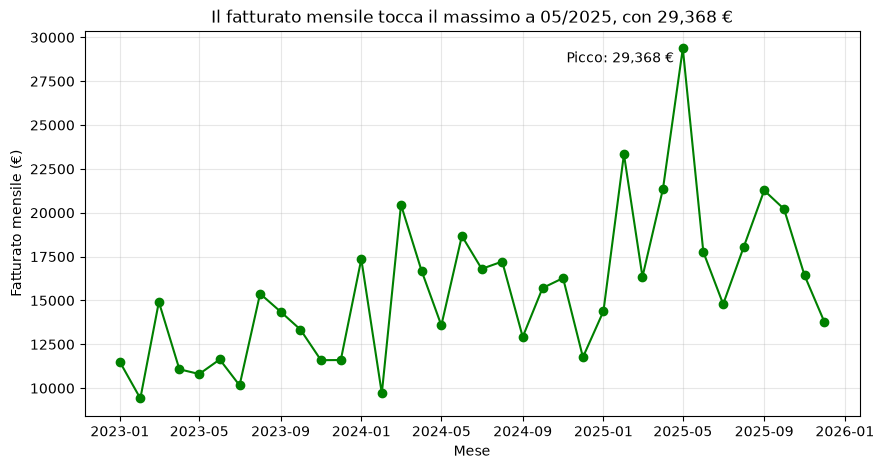

In [69]:
# Passo 1. Importiamo le librerie, ovvero, matplotlib e seaborn per task 1 e 2. 

import matplotlib.pyplot as plt
import seaborn as sns

# Passo 2. Costruisco il grafico con Matplotlib, comincio con il far comparire date nel grafico e non numeri in serie
fatt_mensile = fatturato_mensile.reset_index()

# Passo 3. Lavoro anche sulle date per averle sull'asse x
fatt_mensile["Data"] = pd.to_datetime(dict(year=fatt_mensile["Anno"], month=fatt_mensile["Mese"], day=1))

# Passo 4. Isolo il mese di picco con idxmax() e picco con data e valore
picco_mese = fatt_mensile.loc[fatt_mensile["fatturato_mensile"].idxmax()]
picco_data = picco_mese["Data"]
picco_val = picco_mese["fatturato_mensile"]

# Passo 5. Imposto la dimensione della figura
plt.figure(figsize=(10, 5))

# Passo 6. Fisso date su asse x. e fatturato su y, con marker e color colore verde e puntino per segnalare i picchi
plt.plot(fatt_mensile["Data"], fatt_mensile["fatturato_mensile"], marker="o", color="green")

# Passo 7. Annotazioni sul picco che si visualizzano nel grafico, uso l'f string alla Tommaso e impostop le misure
plt.annotate(f"Picco: {picco_val:,.0f} €",
             xy=(picco_data, picco_val),
             xytext=(-45, -10), textcoords="offset points", ha="center")

# Passo 8. Inserisco titolo, label di x e y, grid per la griglia e infine show
plt.title(f"Il fatturato mensile tocca il massimo a {picco_data:%m/%Y}, con {picco_val:,.0f} €")
plt.xlabel("Mese")
plt.ylabel("Fatturato mensile (€)")
plt.grid(True, alpha=0.3)
plt.show()


Domanda di business richiesta: 

Come cambia il fatturato mensile? Quando raggiunge il massimo? 

Il picco è stato nel maggio 2025 con 29.368 €; l'andamento è sempre molto oscillante da un mese all'altro ma, col tempo, sembra mostrare una tendenza leggermente crescente.

***

2. Seaborn: boxplot di SalesAmount per categoria e heatmap della matrice di correlazione delle variabili numeriche di resellers.


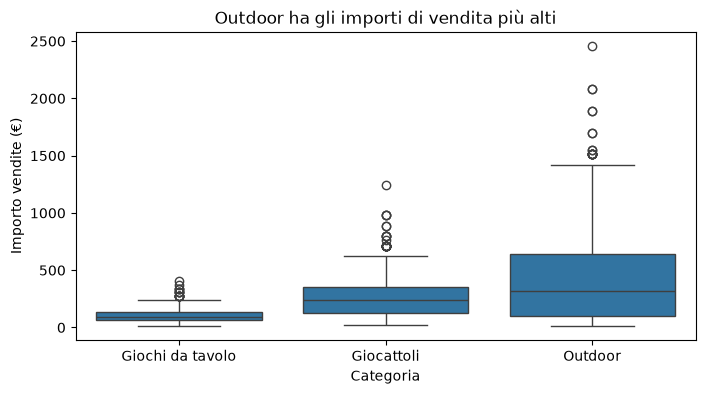

In [70]:
# Passo 1. Creo il grafico boxplot di SalesAmount, stesso procedimento di prima con una sola differenza, comunci da figure
plt.figure(figsize=(8, 4))

# Passo 2. Questo il punto differente, uso boxplot per le x su categoria e y gli importi
sns.boxplot(data=merge_sales, x="Category", y="SalesAmount")

# Passo 3. Il resto come sopra, ma inserisco manualmente il valore
plt.title("Outdoor ha gli importi di vendita più alti")
plt.xlabel("Categoria")
plt.ylabel("Importo vendite (€)")
plt.show()

Domanda di business richiesta: 

Gli importi delle vendite sono simili tra le tre categorie? 

No, gli importi non sono simili, in quanto Outdoor ha gli importi mediani più alti ma anche più dispersi; dopo c'è Giocattoli, infine Giochi da tavolo che ha importi bassi e tutti molto concentrati.

***

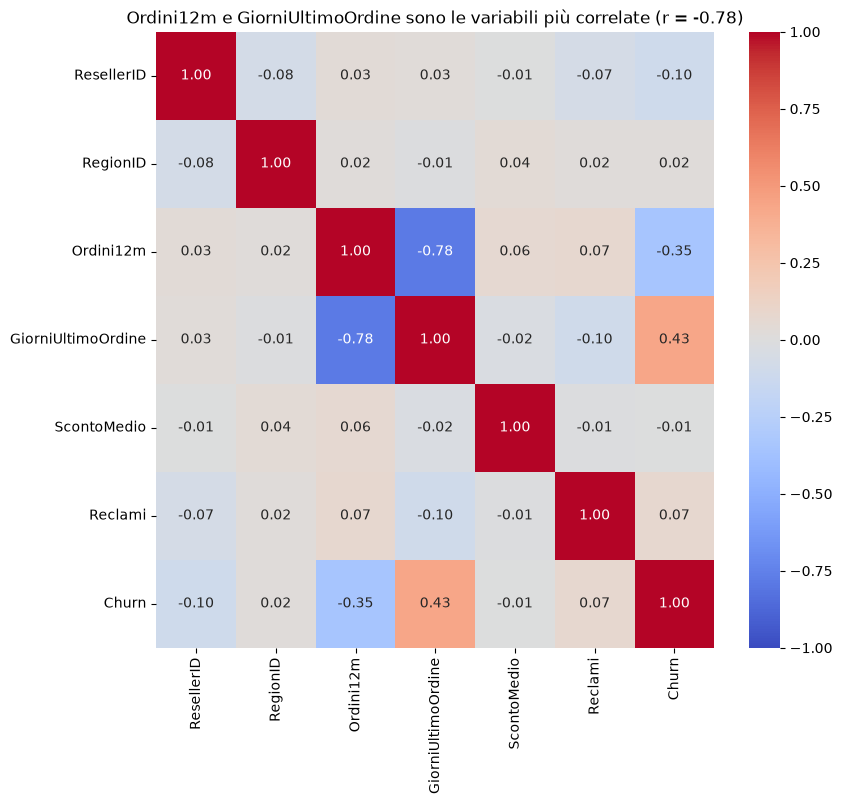

In [72]:
# Passo 1. Creo le heatmap con seaborn e calcolo la matrice di correlazione di Pearson
corr_res = resellers_df.corr()

# Passo 2. Come sopra, imposto la dimensione con figure
plt.figure(figsize=(9, 8))

# Passo 3. Personalizzo il grafico con annot=True, valore in ogni cella; cmap, i colori; vmin/vmax scala da -1 a 1
sns.heatmap(corr_res, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)

# Passo 4. Come sopra, metto titolo manuealmente e mostro il risultato con show
plt.title("Ordini12m e GiorniUltimoOrdine sono le variabili più correlate (r = -0.78)")  
plt.show()

# Nota. Nella heatmap compaiono anche ResellerID e RegionID che, 
# secondo me, andrebbero tolti perché sono identificativi non misure che danno valori, come si tolgono? 
# Direi con un drop dalla colonna resellers e poi fare la correlazione ma non l'ho fatto perché non so sia corretto
# corr_res = resellers_df.drop(columns=["ResellerID", "RegionID"]).corr() 

Domanda di business richiesta: 

Quali caratteristiche dei rivenditori sono più corellati, ovvero, vanno insieme? 

La coppia più correlata è Ordini12m e GiorniUltimoOrdine  con (r = -0.78, negativa): in altre parole, vuol dire che chi ordina di più ha ordinato più recentemente nel tempo. Il Churn, ovvero, il tasso di abbandono è invece legato in positivo ai giorni dall'ultimo ordine, il più recente. 

***

3. Plotly (opzionale): grafico a barre interattivo del fatturato per stato, con quantità totale e numero di transazioni nel tooltip (hover).


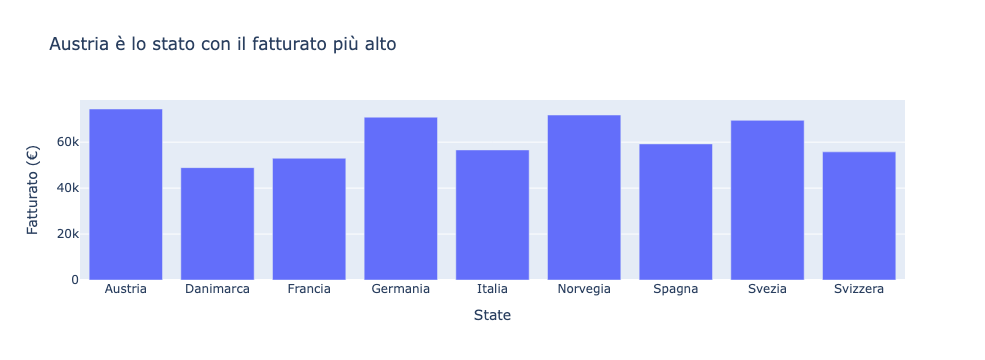

In [68]:
# Passo 1. Importo ploty con l'abbreviazione standard

import plotly.express as px   

# Passo 2. Recupero il fatturato per stato con Groupby usato nle task 3b, uso State al posto di Category/SalesRegion
fatturato_per_stato = merge_sales.groupby("State", as_index=False).agg(
    fatturato=("SalesAmount", "sum"),
    quantita=("Quantity", "sum"),
    transazioni=("SalesID", "count"))


# Passo 3. Creo l'indice per il fatturato più alto e con .loc[indice, "State"] leggo il nome dello stato relativo.
stato_top = per_stato.loc[per_stato["fatturato"].idxmax(), "State"]

# Passo 4. Creo la figura con px.bar, anche qui uso l'f string per il titolo, il resto come sopra
fig = px.bar(per_stato, x="State", y="fatturato",
             hover_data=["quantita", "transazioni"],
             labels={"fatturato": "Fatturato (€)"},
             title=f"{stato_top} è lo stato con il fatturato più alto")
fig.show()

Domanda di Business richiesta: 

Quale stato porta più fatturato?

L'Austria è il primo stato con circa 74.000 €; molto vicino c'è la Norvegia, poi Germania e Svezia (tra 69.000 e 72.000 €.  Danimarca e Francia sono i più bassi, sotto i 55.000 €, circa.

***

Definizione richiesta: criterio di scelta del grafico: andamento nel tempo (linee), confronto tra categorie (barre), distribuzione (boxplot), relazione tra variabili (heatmap o scatter).

Vincolo: il titolo di ogni grafico enuncia il risultato (es. "Il fatturato cresce del 12% nel 2025"), non l'argomento.

Criterio di completamento: grafico a linee, boxplot e heatmap (più le barre Plotly se svolte), ciascuno seguito da una cella
Markdown di due frasi: domanda di business e risposta letta dal grafico.

***

Criterio scelta del grafico, linee, barre, boxpol, heatmap o scatter

Il tipo di grafico che scegliamo dipende sempre dalla domanda posta e dal tipo di dato che abbiamo.

- Se dobbiamo analizzare un andamento temporale impieghiamo il grafico a linee. 

- Se dobbbiamo confrontare delle categorie, impieghiamo invece delle barre. 

- Per vedere invece dati a livello statistico e quindi di distribuizione (valori come mediana, quartili, Outler) utilizziamo il boxplot. 

- Per vedere, infine, unarelazione tra variabili usiamo la heatmap per molte variabili insieme o lo scatter se abbiamo due variabili.

## Task 5 • Correlazione e regressione lineare

Consegna: stimare il fatturato mensile con un modello lineare e usarlo per una previsione dei mesi successivi.

1. Con corr() calcolare la correlazione tra fatturato mensile, quantità mensile e numero di rivenditori attivi nel mese, indicando la coppia più correlata.

In [80]:
# Passo 1. Importo gli strumenti di sklearn 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Passo 2. Mi costruisco una nuova tabelle con groupby da sales che comprenda quantita e rivenditori attivi (prima assenti)
f_mensile = sales_df.groupby(["Anno", "Mese"]).agg(
    fatturato=("SalesAmount", "sum"),
    quantita=("Quantity", "sum"),
    rivenditori_attivi=("ResellerID", "nunique"))

# Passo 3. Dalla nuova tabella mi calcolo l'indice del mese che va da 1 a 36 (mesi dell'analisi) e vedo i 5 con display.
f_mensile["IndiceMese"] = range(1, len(f_mensile) + 1)
display(f_mensile.head())

# Passo 4. Poi, infine faccio la correlazione da f_mensile con .corr() finalmente
f_mensile[["fatturato", "quantita", "rivenditori_attivi"]].corr()

fatturato  quantita  rivenditori_attivi  IndiceMese
Anno Mese                                                     
2023 1       11499.8     214.0                  51           1
     2        9414.9     171.0                  43           2
     3       14917.2     223.0                  48           3
     4       11077.9     220.0                  51           4
     5       10806.7     188.0                  49           5

,fatturato,quantita,rivenditori_attivi
fatturato,1.000000,0.867742,0.556200
quantita,0.867742,1.000000,0.673118
rivenditori_attivi,0.556200,0.673118,1.000000


2. Dopo train_test_split(test_size=0.2, random_state=42), stimare con LinearRegression una regressione semplice (fatturato su indice del mese) e una multipla (indice del mese, quantità, rivenditori attivi).

In [84]:
# Passo 1. Imposto i dati di test come da traccia divido tra 28 mesi di train e 8 di testi su 36
train, test = train_test_split(f_mensile, test_size=0.2, random_state=42)

# Passo 2. Vado di regressione lineare
model_s = LinearRegression()
model_s.fit(train[["IndiceMese"]], train["fatturato"])

# Passo 3. Infine regressione multipla:
model_m = LinearRegression()
model_m.fit(train[["IndiceMese", "quantita", "rivenditori_attivi"]], train["fatturato"])


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ -78.11, 85.31,-229.36]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['IndiceMese','quantita','rivenditori_attivi']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6324
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


3. Riportare coef_, intercept_ e R2 su tràin e test per i due modelli; (opzionale) prevedere con il modello semplice il fatturato dei tre mesi successivi all'ultimo disponibile.

In [96]:
# Passo 1. Vado di R2 con score() del modello su dati di train o test semplice
r2_s_train = model_s.score(train[["IndiceMese"]], train["fatturato"])
r2_s_test = model_s.score(test[["IndiceMese"]], test["fatturato"])

# Passo 2. Vado anche su model_m multipla
r2_m_train = model_m.score(train[["IndiceMese", "quantita", "rivenditori_attivi"]], train["fatturato"])
r2_m_test = model_m.score(test[["IndiceMese", "quantita", "rivenditori_attivi"]], test["fatturato"])

# Passo 3. Stampo i risultati di train e test per r2 semplice e multipla
print("R2 semplice, dati di train:", round(r2_s_train, 3), ", dati di test:", round(r2_s_test, 3))
print("R2 multipla, dati di train:", round(r2_m_train, 3), ", dati di test:", round(r2_m_test, 3))

# Passo 4. Modello di previsione con predict. L'avviso è perché l'ho addestrato con indice mese e qua numeri senza nome
print("Fatturato previsto (€):", model_s.predict([[37], [38], [39]]).round(2)) 

#Passo 5.Stampo una tabella comparativa dei due modelli come da richiesta con tutte le voci relative
Tabella_comparativa = pd.DataFrame({
    "Modello": ["Regressione semplice", "Regressione Multipla"],
    "Intercetta": [model_s.intercept_, model_m.intercept_],
    "Coef. IndiceMese": [model_s.coef_[0], model_m.coef_[0]],
    "Coef. quantita": [None, model_m.coef_[1]],
    "Coef. rivenditori": [None, model_m.coef_[2]],
    "R2 train": [r2_s_train, r2_m_train],
    "R2 test": [r2_s_test, r2_m_test]})

print(Tabella_comparativa)

R2 semplice, dati di train: 0.477 , dati di test: -1.879
R2 multipla, dati di train: 0.836 , dati di test: -0.415
Fatturato previsto (€): [21834.88 22138.46 22442.04]
                Modello    Intercetta  Coef. IndiceMese  Coef. quantita  \
0  Regressione semplice  10602.529065        303.577186             NaN   
1  Regressione Multipla   6323.672621        -78.105342       85.305435   

   Coef. rivenditori  R2 train   R2 test  
0                NaN  0.477107 -1.879054  
1        -229.355013  0.835974 -0.414757  


/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


***

Previsioni del modello semplice per i tre mesi successivi con valori 37, 38, 39: 

- 21.834,88 € (gennaio 2026),
- 22.138,46 €** (febbraio 2026),
- 2.442,04 €** (marzo 2026).

Il coefficiente di IndiceMese è 303,58: in altre parole, la  media del fatturato mensile aumenta di circa 303,58 € per ogni mese. 

***

Definizione richiesta: R2: cos'è, intervallo dei valori, cosa misura e perché una correlazione o un R2 alto non dimostrano un rapporto di causa ed effetto.

Criterio di completamento: tabella comparativa dei due modelli (coefficienti, R2 train, R2 test); tre valori previsti in € se svolta la previsione; coefficiente dell'indice del mese interpretato come variazione in € per mese.

***

R2, correlazione e causa

L'R2 misura quanta parte della variazione del fatturato il modello riesce a spiegare. La misura va da 0 a 1, se è veicina a 1 il modello spiega quasi tutto, se viceversa è vicina allo 0 spiega poco

Una correlazione o R2 alti dicono soltanto che ci sono due numeri, grandezze, che si muovono insieme, ma non dicono nulla se ci sono rapporti causali dell'uno sull'altra: possono essere influenzate da una terza variabile, avere un legame casuale, anche. 